<div style="padding: 28px 32px;
            font-family: 'Georgia', serif;">

  <p style="margin:0; font-size:13px; letter-spacing:3px; text-transform:uppercase; color:#b0477d;">
     Statistics for Data Analytics · CA1 
  </p>

  <h1 style="margin:8px 0 4px 0; font-size:32px;">
    Payment Behaviour at Cosmovision
  </h1>

  <p style="margin:4px 0; font-size:15px;"><b>Student:</b> María Fernanda López Díaz</p>
  <p style="margin:4px 0; font-size:15px;"><b>Student ID:</b> 2026794</p>
  <p style="margin:4px 0; font-size:15px;"><b>Lecturer:</b> Taufique Ahmed</p>
  <p style="margin:4px 0; font-size:15px;"><b>GitHub:</b>
    <a href="https://github.com/mafs794/payments-statistical-techniques-ca1.git" style="color:#b0477d;">
      github.com/mafs794/payments-statistical-techniques-ca1.git</a></p>
</div>

In [1]:
import pandas as pd 
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
EXPORT_DATE = pd.Timestamp("2026-02-10")

In [2]:
def print_inventory(dct):
    print("Data:")
    for item, amount in dct.items():  
        print("{}: {}".format(item, amount))

def classify(plan):
    p = str(plan).lower()
    has_internet = any(w in p for w in ["internet", "megas", "mg"])
    has_cable = any(w in p for w in ["cable", "tv"])
    has_courtesy = any(w in p for w in ["cortesia", "cortesía"])
    if has_courtesy:
        return "Courtesy"
    elif has_internet and has_cable:
        return "Bundle"
    elif has_internet:
        return "Internet"
    elif has_cable:
        return "Cable"
    return "Other"

def describe_var(col, df):
    s = df[col].dropna()
    stats = {
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode()[0],        # [0] = first mode only (mode() returns a list)
        "min": s.min(),
        "max": s.max(),
        "range": s.max() - s.min(),
        "variance": s.var(),
        "std": s.std(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "skewness": s.skew(),
        "kurtosis": s.kurt(),
    }
    return pd.Series(stats, name=col).round(2)

In [3]:
# --- Rename columns from spanish to english ---
english_columns = ["id", "status", "area", "sub_area", "collector", "plan", "fee", "ad_tvs", "ad_fee", "balance", "+nov_balance", "dic_balance", 
                   "jan_balance", "feb_balance", "registration_date", "termination_date", "reconnection_date", "last_payment_date", "installation_day", 
                   "payday", "year_paid", "month_paid", "visit_date"]
raw_data = pd.read_excel("data/raw/data.xlsx", sheet_name="Sheet1", names=english_columns, header=1)

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">1. Data Preparation</h2>
  <p style="margin:0; font-size:15px; line-height:1.6;">
    In this section I load the anonymised February 2026 service report, check data types 
    and missing values, and derive new variables such as tenure, days since last payment
    and months owed, all calculated relative to the export date.
  </p>
</div>

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h2 style="margin:0 0 4px 0; font-size:22px;">1.1 Read Data</h2>

</div>

In [4]:
# --- Visualize first five rows of the data ---
raw_data.head()

,id,status,area,sub_area,collector,plan,fee,ad_tvs,ad_fee,balance,...,feb_balance,registration_date,termination_date,reconnection_date,last_payment_date,installation_day,payday,year_paid,month_paid,visit_date
0,100,ALTA,4 - ALDEA BUENA VISTA,13 - CALLE PRINCIPAL,mario,429 - INTERNET 60 MEGAS FO CON CABLE TV,199,0,0,199,...,199,28/11/2023,NaN,NaN,04/02/2026,28,4,2026,1,NaN
1,101,ALTA,1 - MILPAS ALTAS,4 - MAGDALENA,mario,376 - INTERNET 25 MEGAS FO CON CABLE TV FO,199,0,0,376,...,199,02/02/2021,05/02/2021,09/02/2021,21/01/2026,9,21,2025,12,NaN
2,102,ALTA,1 - MILPAS ALTAS,4 - MAGDALENA,mario,6 - INTERNET 10 MEGAS FIBRA OPTICA CON CABLE T...,150,0,0,0,...,0,02/02/2021,NaN,NaN,05/02/2026,2,5,2026,2,NaN
3,103,ALTA,1 - MILPAS ALTAS,4 - MAGDALENA,mario,6 - INTERNET 10 MEGAS FIBRA OPTICA CON CABLE T...,150,0,0,150,...,150,01/03/2021,NaN,NaN,24/01/2026,1,24,2026,1,NaN
4,104,ALTA,1 - MILPAS ALTAS,4 - MAGDALENA,daniel,6 - INTERNET 10 MEGAS FIBRA OPTICA CON CABLE T...,150,0,0,0,...,0,02/03/2021,NaN,NaN,05/02/2026,2,5,2026,2,NaN


In [5]:
raw_data.shape

(1013, 23)

In [6]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1013 entries, 0 to 1012
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   id                 1013 non-null   int64
 1   status             1013 non-null   str  
 2   area               1013 non-null   str  
 3   sub_area           1013 non-null   str  
 4   collector          1013 non-null   str  
 5   plan               1013 non-null   str  
 6   fee                1013 non-null   int64
 7   ad_tvs             1013 non-null   int64
 8   ad_fee             1013 non-null   int64
 9   balance            1013 non-null   int64
 10  +nov_balance       1013 non-null   int64
 11  dic_balance        1013 non-null   int64
 12  jan_balance        1013 non-null   int64
 13  feb_balance        1013 non-null   int64
 14  registration_date  1013 non-null   str  
 15  termination_date   46 non-null     str  
 16  reconnection_date  56 non-null     str  
 17  last_payment_date  1002 n

In [7]:
# --- Check Missing Values ---
raw_data.isnull().sum()

id                      0
status                  0
area                    0
sub_area                0
collector               0
plan                    0
fee                     0
ad_tvs                  0
ad_fee                  0
balance                 0
+nov_balance            0
dic_balance             0
jan_balance             0
feb_balance             0
registration_date       0
termination_date      967
reconnection_date     957
last_payment_date      11
installation_day        0
payday                  0
year_paid               0
month_paid              0
visit_date           1009
dtype: int64

The fact that the customer doesn't have any of these dates doesn't mean the data is incorrect. It means the customer has never canceled their service and has never requested a reconnection. 
Regarding the date of the visit, it means that these customers were never visited by a debt collector at their home.

In [8]:
no_payment = raw_data[raw_data["last_payment_date"].isna()]
no_payment[["id", "plan", "status", "registration_date", "fee"]]

,id,plan,status,registration_date,fee
358,458,396 - INTERNET 35 MEGAS CORTESIA,ALTA,27/05/2024,0
366,466,396 - INTERNET 35 MEGAS CORTESIA,ALTA,12/06/2024,0
500,600,427 - INTERNET DE CORTESIA,ALTA,12/11/2024,0
614,714,427 - INTERNET DE CORTESIA,ALTA,04/03/2025,0
627,727,427 - INTERNET DE CORTESIA,ALTA,10/03/2025,0
634,734,427 - INTERNET DE CORTESIA,ALTA,12/03/2025,0
698,798,427 - INTERNET DE CORTESIA,ALTA,21/05/2025,0
755,855,427 - INTERNET DE CORTESIA,ALTA,16/07/2025,0
756,856,427 - INTERNET DE CORTESIA,ALTA,16/07/2025,0
821,921,427 - INTERNET DE CORTESIA,ALTA,26/09/2025,0


The 11 customers who do not have a final payment date are customers who have a complimentary service (cortesia = courtesy). 

In [9]:
# --- Check Unique Values ---
raw_data.nunique()

id                   1013
status                  2
area                    6
sub_area               26
collector               5
plan                   36
fee                    13
ad_tvs                  6
ad_fee                  2
balance                79
+nov_balance            9
dic_balance             6
jan_balance            31
feb_balance            40
registration_date     603
termination_date       40
reconnection_date      51
last_payment_date      94
installation_day       31
payday                 31
year_paid               4
month_paid             11
visit_date              4
dtype: int64

In [10]:
print("Unique Values in 'status':", raw_data['status'].unique())

Unique Values in 'status': <StringArray>
['ALTA', 'PENDIENTE CORTE']
Length: 2, dtype: str


In [11]:
print("Unique Values in 'Area':", raw_data['area'].unique())

Unique Values in 'Area': <StringArray>
[  '4 - ALDEA BUENA VISTA',        '1 - MILPAS ALTAS',
 '8 - COLONIA EL NAZARENO',       '6 - EL MEMBRILLAL',
          '5 - SAN MIGUEL',    '7 - MAGDALENA CENTRO']
Length: 6, dtype: str


In [12]:
for plan in sorted(raw_data['plan'].unique()):
    print(plan)

1 - CABLE TV FO
160 - INTERNET 10 MEGAS FO SIN TV
240 - INTERNET 3 MG INALAMBRICO CON CONTRATO
344 - INTERNET 50 MEGAS FO CON CABLE TV FO
346 - INTERNET 100 MEGAS FO CON CABLE TV FO
370 - CABLE TV FO
376 - INTERNET 25 MEGAS FO CON CABLE TV FO
378 - INTERNET 35 MEGAS FO CON CABLE TV FO
379 - INTERNET 50 MEGAS FO CON CABLE TV FO
382 - INTERNET 25 MEGAS FO SIN CABLE TV
384 - INTERNET 50 MEGAS FO SIN CABLE TV
388 - INTERNET 15 MEGAS FO
389 - INTERNET DE 10 MEGAS + CABLE
396 - INTERNET 35 MEGAS CORTESIA
402 - INTERNET 15MG INALAMBRICO
405 - INTERNET 100 MEGAS FO SIN CABLE TV
417 - INTERNET 30 MEGAS FO CON CABLE TV
418 - INTERNET 20 MEGAS FO CON CABLE TV
422 - INTERNET 50 MEGAS FO CON CABLE
427 - INTERNET DE CORTESIA
428 - INTERNET 40 MEGAS FO CON CABLE TV
429 - INTERNET 60 MEGAS FO CON CABLE TV
430 - INTERNET 100 MEGAS FO CON CABLE TV
435 - INTERNET 35 MEGAS FIBRA OPTICA
441 - INTERNET 75 MEGAS FO CON CABLE TV
442 - INTERNET 150 MEGAS FO CON CABLE TV
449 - INTERNET 200 MEGAS FO SIN TV
452 -

The plan column has 36 different service plan names. As you can see in the list above, many vary only in the speed contracted by the customer. The plan column will remain, but for the purposes of this exercise, a new column will be created to indicate only the type of service the customer has, for example: 
Internet only
Cable only
Cable and internet (Bundle)

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h2 style="margin:0 0 4px 0; font-size:22px;">1.2 Deriving new features</h2>
  <p style="margin:0; font-size:16px; line-height:1.5; color:#7a4a6a;">
    Creating new features for the normal and binomal distribution.
  </p>
</div>

In [13]:
process_data = raw_data.copy()    #Create a copy of the raw data to process and clean

#Convert date columns to datetime format with day first
for col in ["registration_date", "reconnection_date"]:        
    process_data[col] = pd.to_datetime(process_data[col], dayfirst=True, errors="coerce")

# Tenure counts from reinstatement if the customer came back, otherwise from installation
process_data["registration_date"] = process_data["reconnection_date"].fillna(process_data["registration_date"])
process_data["tenure_months"] = ((EXPORT_DATE - process_data["registration_date"]).dt.days / 30.44).round(1)

# Checks
print(process_data["tenure_months"].describe())
print("Missing:", process_data["tenure_months"].isna().sum())
print("Reinstated customers:", process_data["reconnection_date"].notna().sum())

count    1013.000000
mean       16.516979
std        12.706680
min         0.000000
25%         6.500000
50%        14.200000
75%        24.100000
max        60.200000
Name: tenure_months, dtype: float64
Missing: 0
Reinstated customers: 56


In [14]:
# --- Days since last payment ---
process_data["last_payment_date"] = pd.to_datetime(process_data["last_payment_date"], dayfirst=True, errors="coerce")
process_data["days_since_payment"] = (EXPORT_DATE - process_data["last_payment_date"]).dt.days

#Checks
print(process_data["days_since_payment"].describe())
print("Missing:", process_data["days_since_payment"].isna().sum())

count    1002.000000
mean       24.411178
std        41.068893
min         0.000000
25%         6.000000
50%        20.000000
75%        30.000000
max       860.000000
Name: days_since_payment, dtype: float64
Missing: 11


In [15]:
# usar el 100 por que es el minimo de mensualidad al mes, el precio del servicio de cable 
process_data[(process_data["balance"] > 0) & (process_data["balance"] < 100)].shape[0]

2

In [16]:
# --- Months Owed ---
process_data["monthly_fee"] = process_data["fee"] + process_data["ad_fee"].fillna(0)
process_data["months_owed"] = np.where(
    process_data["balance"] > 0,                              
    np.ceil(process_data["balance"] / process_data["monthly_fee"]),
    0
).astype(int)

print(process_data["months_owed"].value_counts().sort_index())
print("Missing:", process_data["months_owed"].isna().sum())
print("Fee = 0:", (process_data["monthly_fee"] == 0).sum())


months_owed
0    313
1    463
2    199
3     21
4     14
5      3
Name: count, dtype: int64
Missing: 0
Fee = 0: 14


There are 14 rows with Fee = 0, but only 11 rows that had no last paymente date. That we assumed were the ones with a courtesy service.

In [17]:
no_fee = process_data[(process_data["fee"] == 0)]
no_fee[["id", "plan", "status", "registration_date", "fee", "last_payment_date"]]

,id,plan,status,registration_date,fee,last_payment_date
176,276,427 - INTERNET DE CORTESIA,ALTA,2023-11-21,0,2025-09-18
305,405,427 - INTERNET DE CORTESIA,ALTA,2024-03-07,0,2024-03-08
358,458,396 - INTERNET 35 MEGAS CORTESIA,ALTA,2024-05-27,0,NaT
366,466,396 - INTERNET 35 MEGAS CORTESIA,ALTA,2024-06-12,0,NaT
500,600,427 - INTERNET DE CORTESIA,ALTA,2024-11-12,0,NaT
614,714,427 - INTERNET DE CORTESIA,ALTA,2025-03-04,0,NaT
627,727,427 - INTERNET DE CORTESIA,ALTA,2025-03-10,0,NaT
634,734,427 - INTERNET DE CORTESIA,ALTA,2025-03-12,0,NaT
698,798,427 - INTERNET DE CORTESIA,ALTA,2025-05-21,0,NaT
755,855,427 - INTERNET DE CORTESIA,ALTA,2025-07-16,0,NaT


In [18]:
# --- Service Type  ---
process_data["service_type"] = process_data["plan"].apply(classify)

In [19]:
process_data["service_type"].unique()

<StringArray>
['Bundle', 'Internet', 'Cable', 'Courtesy']
Length: 4, dtype: str

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h1 style="margin:0 0 6px 0; color:#7a4a6a;">2. Descriptive Statistics</h1>
</div>

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h2 style="margin:0 0 4px 0; font-size:22px;">2.1 Numerical Summary</h2>
</div>

In [20]:
process_data.describe(include="int64")

,id,fee,ad_tvs,ad_fee,balance,+nov_balance,dic_balance,jan_balance,feb_balance,installation_day,payday,year_paid,month_paid,monthly_fee,months_owed
count,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000,1013.000000
mean,606.000000,175.430405,0.024679,0.024679,170.729516,3.642646,5.908193,39.653504,121.525173,14.826259,12.464956,2015.755183,3.879566,175.455084,0.982231
std,292.572213,40.728984,0.298850,0.785480,154.192227,28.670105,31.216547,73.739348,86.326448,9.314733,8.290311,142.039462,4.405946,40.781147,0.872097
min,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,353.000000,150.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,6.000000,2026.000000,1.000000,150.000000,0.000000
50%,606.000000,175.000000,0.000000,0.000000,175.000000,0.000000,0.000000,0.000000,150.000000,14.000000,10.000000,2026.000000,2.000000,175.000000,1.000000
75%,859.000000,199.000000,0.000000,0.000000,233.000000,0.000000,0.000000,0.000000,188.000000,23.000000,19.000000,2026.000000,3.000000,199.000000,1.000000
max,1112.000000,599.000000,6.000000,25.000000,992.000000,395.000000,199.000000,299.000000,575.000000,31.000000,31.000000,2026.000000,12.000000,599.000000,5.000000


In [21]:
process_data.describe(include="str")

,status,area,sub_area,collector,plan,termination_date,visit_date,service_type
count,1013,1013,1013,1013,1013,46,4,1013
unique,2,6,26,5,36,40,4,4
top,ALTA,1 - MILPAS ALTAS,4 - MAGDALENA,mario,429 - INTERNET 60 MEGAS FO CON CABLE TV,23/06/2025,13/10/2023,Bundle
freq,1004,709,701,710,298,3,1,901


In [22]:
process_data["status"].value_counts()

status
ALTA               1004
PENDIENTE CORTE       9
Name: count, dtype: int64

In [53]:
process_data["area"].value_counts()

area
1 - MILPAS ALTAS           696
4 - ALDEA BUENA VISTA      155
5 - SAN MIGUEL             104
8 - COLONIA EL NAZARENO     38
6 - EL MEMBRILLAL            4
7 - MAGDALENA CENTRO         2
Name: count, dtype: int64

In [24]:
process_data["service_type"].value_counts()

service_type
Bundle      901
Cable        58
Internet     40
Courtesy     14
Name: count, dtype: int64

In [25]:
pd.crosstab(process_data["service_type"], process_data["status"], margins=True)

status,ALTA,PENDIENTE CORTE,All
service_type,,,
Bundle,893,8,901
Cable,57,1,58
Courtesy,14,0,14
Internet,40,0,40
All,1004,9,1013


Only 9 of 1013 customers are "pendiente corte" (pending cutting). Disconnections were a rare event in the month of january to feb.

In [26]:
pd.crosstab(process_data["months_owed"], process_data["service_type"], margins=True)

service_type,Bundle,Cable,Courtesy,Internet,All
months_owed,,,,,
0,258,27,14,14,313
1,432,14,0,17,463
2,183,8,0,8,199
3,13,7,0,1,21
4,13,1,0,0,14
5,2,1,0,0,3
All,901,58,14,40,1013


In [27]:
(pd.crosstab(process_data["months_owed"], process_data["service_type"], normalize="columns") * 100).round(1)

service_type,Bundle,Cable,Courtesy,Internet
months_owed,,,,
0,28.6,46.6,100.0,35.0
1,47.9,24.1,0.0,42.5
2,20.3,13.8,0.0,20.0
3,1.4,12.1,0.0,2.5
4,1.4,1.7,0.0,0.0
5,0.2,1.7,0.0,0.0


In [28]:
summary = pd.DataFrame({
    "owes_0":   process_data.groupby("service_type")["months_owed"].apply(lambda x: (x == 0).mean() * 100),
    "owes_1+":  process_data.groupby("service_type")["months_owed"].apply(lambda x: (x >= 1).mean() * 100),
    "owes_3+":  process_data.groupby("service_type")["months_owed"].apply(lambda x: (x >= 3).mean() * 100),
}).round(1)
summary

,owes_0,owes_1+,owes_3+
service_type,,,
Bundle,28.6,71.4,3.1
Cable,46.6,53.4,15.5
Courtesy,100.0,0.0,0.0
Internet,35.0,65.0,2.5


There are many fully up to date cable customers, but 15.5% owe 3 or month months, five times the bundle rate.

In [29]:
pd.concat([describe_var(c, process_data) for c in ["tenure_months", "months_owed", "monthly_fee"]], axis=1)

,tenure_months,months_owed,monthly_fee
mean,16.52,0.98,175.46
median,14.20,1.00,175.00
mode,4.30,1.00,199.00
min,0.00,0.00,0.00
max,60.20,5.00,599.00
range,60.20,5.00,599.00
variance,161.46,0.76,1663.10
std,12.71,0.87,40.78
Q1,6.50,0.00,150.00
Q3,24.10,1.00,199.00


1. **Tenure**: mean 16.5 > median 14.2 > mode 4.3 and skewness 1.23. It is right-skewed. The customer base is fairly new.
2. **Months owed**: median 1 and Q3 1. Most customer owe about one month. Paying a month behind is normal at Cosmovision.
3. **Monthly fee**: these values still include the 14 courtesy accounts (fee = 0). The updated summary is shown after they are removed below.

In [30]:
before = len(process_data)
process_data = process_data[process_data["service_type"] != "Courtesy"]
print(f"Removed {before - len(process_data)} courtesy accounts")

Removed 14 courtesy accounts


In [31]:
# Monthly fee summary after removing the courtesy accounts
describe_var("monthly_fee", process_data)

mean         177.91
median       175.00
mode         199.00
min          100.00
max          599.00
range        499.00
variance    1248.53
std           35.33
Q1           150.00
Q3           199.00
IQR           49.00
skewness       1.73
kurtosis      20.77
Name: monthly_fee, dtype: float64

After removing the courtesy accounts (fee = 0), the median monthly fee is Q175, the price of the cheapest bundle, and the mean is Q177.9. The fee is right-skewed (1.73) and has a high kurtosis (20.77): most customers pay one of a few standard prices, with a few much higher fees.

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h2 style="margin:0 0 4px 0; font-size:22px;">2.2 Plots</h2>
</div>

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h3 style="margin:0 0 4px 0; font-size:18px;">2.2.1 Histogram of tenure</h3>
  <p>Reason: shows the shape of the distribution and confirms the right skew found in the summary statistics.</p>
</div>

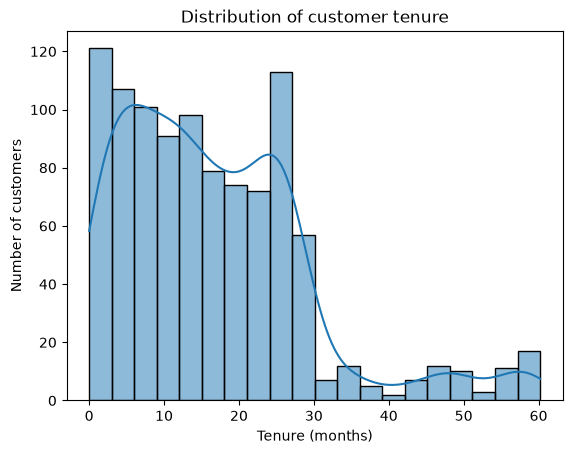

In [32]:
sns.histplot(process_data["tenure_months"], kde=True, bins=20)
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.title("Distribution of customer tenure")
plt.show()

Most customers have under 30 months of tenure. There's a spike at about 25-27 months and a small group of long standing customers. Tenure drops at around 30 months, which coincide with the opening of the local branch in 2023.

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h3 style="margin:0 0 4px 0; font-size:18px;">2.2.2 Boxplot of months owed by service type</h3>
  <p>Reason: compares the spread and outliers of debt between service types.</p>
</div>

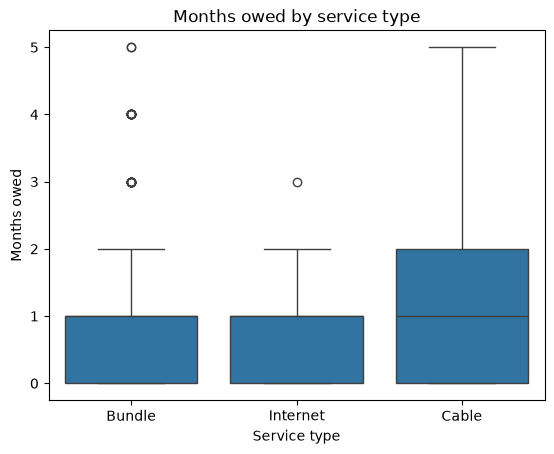

In [33]:
sns.boxplot(data=process_data, x="service_type", y="months_owed")
plt.xlabel("Service type")
plt.ylabel("Months owed")
plt.title("Months owed by service type")
plt.show()

In bundle and internet the box goes from 0 to 1 month, and 3+ months appear as outlier, so a large debt us unusual for customers with this service type. Compare to cable, that a large debt isn't an outlier for them. 

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h3 style="margin:0 0 4px 0; font-size:18px;">2.2.3 Stacked bar chart of months owed by service type</h3>
  <p>Reason: shows the polarisation of cable customers.</p>
</div>

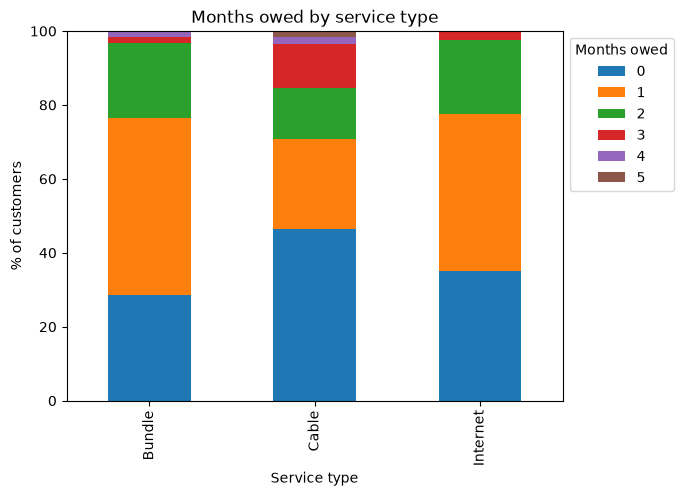

In [34]:
ct = pd.crosstab(process_data["service_type"], process_data["months_owed"], normalize="index") * 100
ct.plot(kind="bar", stacked=True)
plt.xlabel("Service type")
plt.ylabel("% of customers")
plt.title("Months owed by service type")
plt.legend(title="Months owed", bbox_to_anchor=(1, 1))
plt.show()

Paying a month behind is the usual pattern.

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h2 style="margin:0 0 4px 0; font-size:22px;">2.2 IQR</h2>
</div>

In [35]:
q1 = process_data["monthly_fee"].quantile(0.25)
q3 = process_data["monthly_fee"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = process_data[(process_data["monthly_fee"] < lower_bound) | (process_data["monthly_fee"] > upper_bound)]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
print("Low outliers:", (process_data["monthly_fee"] < lower_bound).sum())
print("High outliers:", (process_data["monthly_fee"] > upper_bound).sum())

Lower bound: 76.5
Upper bound: 272.5
Number of outliers: 12
Low outliers: 0
High outliers: 12


In [36]:
# Which plans are the outliers?
outliers["plan"].value_counts()

plan
379 - INTERNET 50 MEGAS FO CON CABLE TV FO            3
384 - INTERNET 50 MEGAS FO SIN CABLE TV               2
453 - INTERNET 200 MEGAS FIBRA OPTICA CON CABLE TV    2
449 - INTERNET 200 MEGAS FO SIN TV                    1
346 - INTERNET 100 MEGAS FO CON CABLE TV FO           1
344 - INTERNET 50 MEGAS FO CON CABLE TV FO            1
442 - INTERNET 150 MEGAS FO CON CABLE TV              1
430 - INTERNET 100 MEGAS FO CON CABLE TV              1
Name: count, dtype: int64

In [37]:
(outliers.groupby("plan")["monthly_fee"]
         .agg(customers="count", fee="mean")
         .sort_values("fee")
         .round(2))

,customers,fee
plan,,
430 - INTERNET 100 MEGAS FO CON CABLE TV,1,274.0
384 - INTERNET 50 MEGAS FO SIN CABLE TV,2,275.0
449 - INTERNET 200 MEGAS FO SIN TV,1,280.0
344 - INTERNET 50 MEGAS FO CON CABLE TV FO,1,299.0
379 - INTERNET 50 MEGAS FO CON CABLE TV FO,3,299.0
442 - INTERNET 150 MEGAS FO CON CABLE TV,1,299.0
453 - INTERNET 200 MEGAS FIBRA OPTICA CON CABLE TV,2,299.0
346 - INTERNET 100 MEGAS FO CON CABLE TV FO,1,599.0


Using the IQR method, fees below Q76.5 or above Q272.5 were classed as outliers. All 12 outliers are high fees: most are bundles of 100–200 Mb with cable TV at Q299, which are real premium prices. However, some look inconsistent: a 50 Mb internet-only plan at Q275 costs more than several bundles, suggesting an old price that was never updated, and one 100 Mb bundle is charged Q599, which may be an administrative error. These values were kept, as they reflect what customers are actually billed, but they should be reviewed. They also explain the high kurtosis (20.77): most customers pay one of a few standard prices (Q150–Q199), with a small number of much higher fees.

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h2 style="margin:0 0 4px 0; font-size:22px;">2.4 Key findings</h2>
</div>

- **Paying one month behind is the norm.** The median customer owes 1 month and 70%  owe at least one month, while only 0.9% are pending disconnection. 
- **Cable-only customers are polarised.** 47% are fully up to date, but 15.5% owe 3+ months, about five times the bundle rate (3.1%). This is probably because cable service cannot be suspended remotely.
- **Bundles dominate the portfolio.** About 90% of customers have internet + cable.
- **The customer base is young.** Tenure is right-skewed: most customers joined after the branch opened in 2023.
- **Fees cluster around a few standard prices** (Q150–Q199), with 12 high outliers; some of them suggest outdated or incorrect prices.

**Limitations:** single February 2026 snapshot; active customers only ; rows without a last payment and courtesy accounts removed; small groups; results show associations, not causes.

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">3. Discret Distributions</h2>
</div>

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h2 style="margin:0 0 4px 0; font-size:22px;">3.1 Binomal </h2>
</div>

$$P(X = k) = \binom{n}{k} p^k (1-p)^{n-k}$$

1. Create the yes/no variable and estimate p

In [38]:
process_data["owes"] = (process_data["months_owed"] >= 1).astype(int)   # 1 = owes at least 1 month, 0 = up to date
p = process_data["owes"].mean()
print("p =", round(p, 3))

p = 0.701


p = 0.701: 70.1% of customers owe at least one month

2. Define the scenario: a group of n = 20 customers

In [39]:
n = 20
k = np.arange(0, n + 1)
pmf = stats.binom.pmf(k, n, p)

print("Expected number who owe (n·p):", round(n * p, 2))
print("Standard deviation:", round(np.sqrt(n * p * (1 - p)), 2))
print("P(X = 14):", round(stats.binom.pmf(14, n, p), 3))
print("P(X ≥ 15):", round(1 - stats.binom.cdf(14, n, p), 3))
print("P(X ≤ 10):", round(stats.binom.cdf(10, n, p), 3))

Expected number who owe (n·p): 14.01
Standard deviation: 2.05
P(X = 14): 0.192
P(X ≥ 15): 0.419
P(X ≤ 10): 0.047


In a group of 20 customers, about 14 will owe. Somewhere between 12 and 16 is normal.
Only 10 or fewer owing is rare (about 5%), so that would be an unusually good group.

3. Plot the distribution

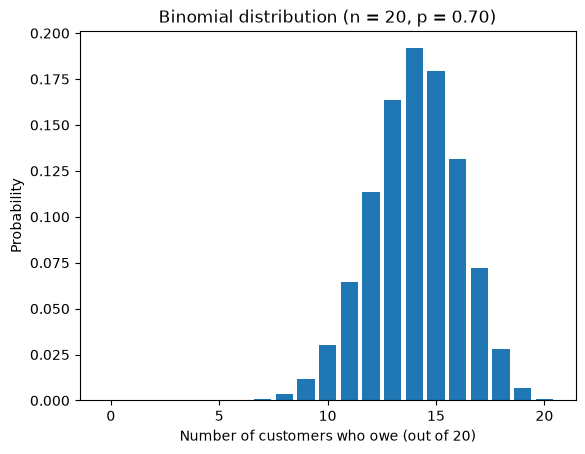

In [40]:
plt.bar(k, pmf)
plt.xlabel("Number of customers who owe (out of 20)")
plt.ylabel("Probability")
plt.title(f"Binomial distribution (n = {n}, p = {p:.2f})")
plt.show()

4. Check it against the real data

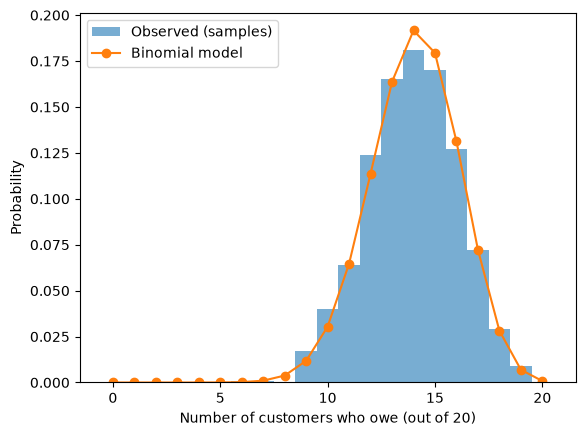

In [41]:
# Take 1,000 random groups of 20 real customers and count how many owe in each
counts = [process_data["owes"].sample(n, replace=True).sum() for i in range(1000)]

plt.hist(counts, bins=np.arange(-0.5, n + 1.5), density=True, alpha=0.6, label="Observed (samples)")
plt.plot(k, pmf, "o-", label="Binomial model")
plt.xlabel("Number of customers who owe (out of 20)")
plt.ylabel("Probability")
plt.legend()
plt.show()

About 70% of customers owe at least one month. In a group of 20 customers, around 14 are expected to owe, and between 12 and 16 is normal. Having 10 or fewer debtors is rare (4.7%). The model matches the real data well, but it assumes all customers behave the same, which is not fully true (for example, cable-only customers).

5. Large sample

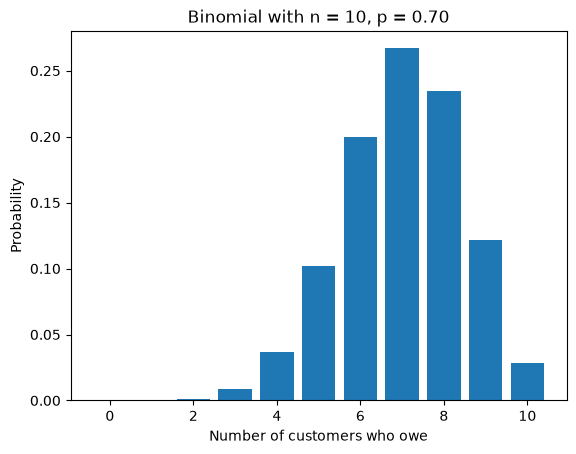

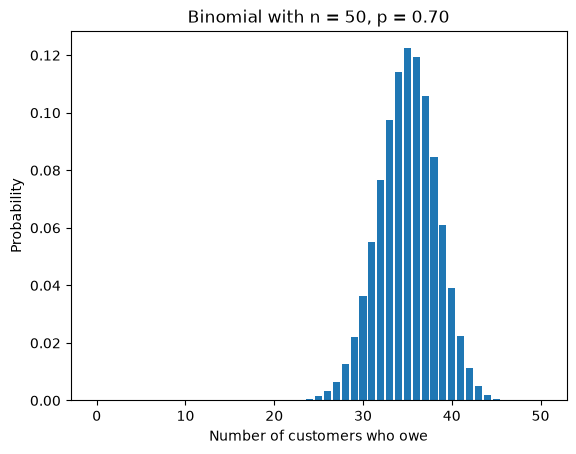

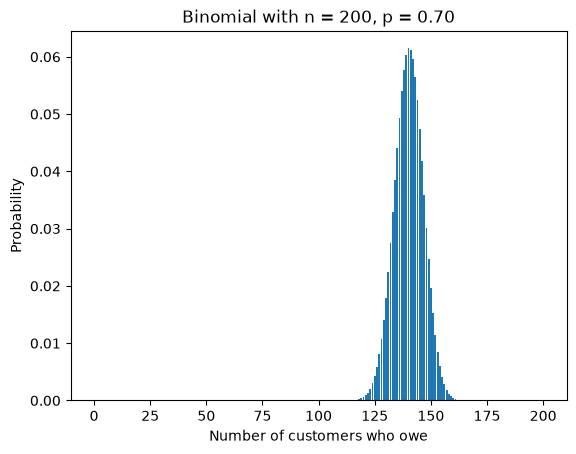

In [42]:
for n in [10, 50, 200]:
    k = np.arange(0, n + 1)
    plt.bar(k, stats.binom.pmf(k, n, p))
    plt.xlabel("Number of customers who owe")
    plt.ylabel("Probability")
    plt.title(f"Binomial with n = {n}, p = {p:.2f}")
    plt.show()

When the group of customers gets bigger, the chart looks more like a bell. With 200 customers, it looks almost like a Normal distribution. So for big groups, we can use the Normal distribution instead of the Binomial.

<div style="margin:20px 0 8px 12px;
            font-family:'Georgia', serif; color:#5a2a4a;">
  <h2 style="margin:0 0 4px 0; font-size:22px;">3.2 Poisson </h2>
</div>

$$P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!}$$

1. Calculate λ and compare mean vs variance

In [43]:
lam = process_data["months_owed"].mean()
print("λ (mean) =", round(lam, 2))
print("Variance =", round(process_data["months_owed"].var(), 2))

λ (mean) = 1.0
Variance = 0.76


2. Observed vs expected (table)

In [44]:
k = np.arange(0, 6)
observed = process_data["months_owed"].value_counts().sort_index()
expected = stats.poisson.pmf(k, lam) * len(process_data)

comparison = pd.DataFrame({"observed": observed, "expected": expected.round(0)}, index=k)
comparison

,observed,expected
0,299,369.0
1,463,368.0
2,199,183.0
3,21,61.0
4,14,15.0
5,3,3.0


3. Plot both side by side

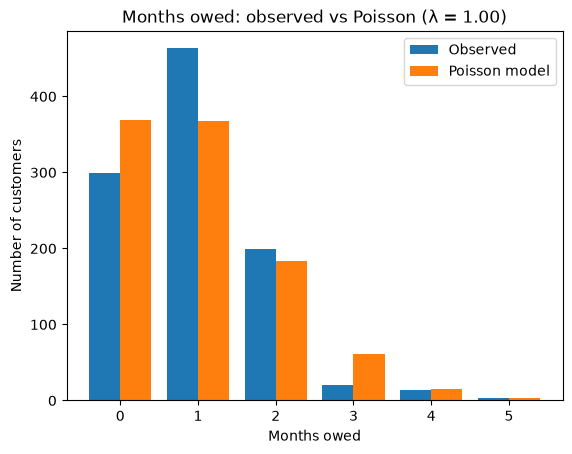

In [45]:
plt.bar(k - 0.2, comparison["observed"], width=0.4, label="Observed")
plt.bar(k + 0.2, comparison["expected"], width=0.4, label="Poisson model")
plt.xlabel("Months owed")
plt.ylabel("Number of customers")
plt.title(f"Months owed: observed vs Poisson (λ = {lam:.2f})")
plt.legend()
plt.show()

The average number of months owed is 1.0, but the variance is lower (0.76), so the data is more concentrated than a Poisson distribution expects. More customers owe exactly 1 month than the model predicts, and fewer owe 0 or 3 months. This makes sense for Cosmovision: the suspension date pushes customers to pay before their debt grows, so most stay around one month behind. The Poisson is a reasonable first model, but it does not fully fit the data.

4. Large samples

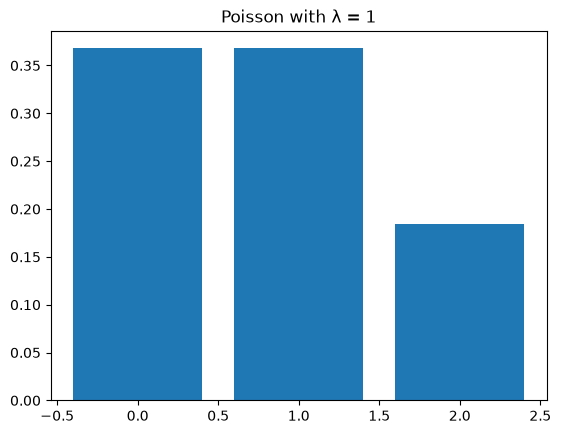

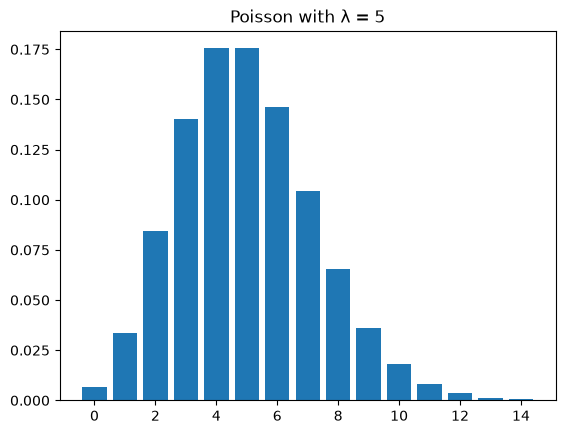

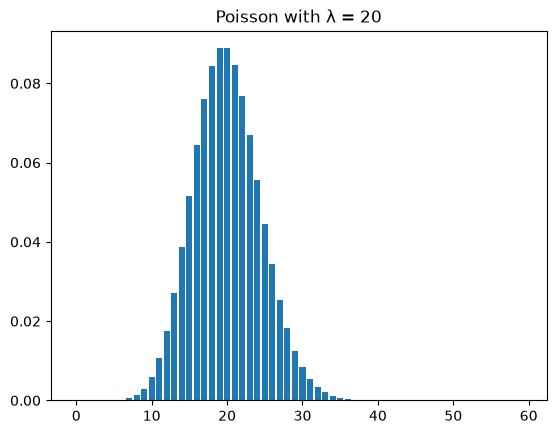

In [46]:
for lam_test in [1, 5, 20]:
    k_test = np.arange(0, lam_test * 3)
    plt.bar(k_test, stats.poisson.pmf(k_test, lam_test))
    plt.title(f"Poisson with λ = {lam_test}")
    plt.show()

As λ increases, the Poisson distribution becomes more symmetric and bell-shaped. With λ = 20, it looks almost like a Normal distribution. With our λ = 1, the shape is skewed, so the Normal would not be a good approximation for months owed.

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">4. Normal Distribution</h2>
</div>

1. Histogram

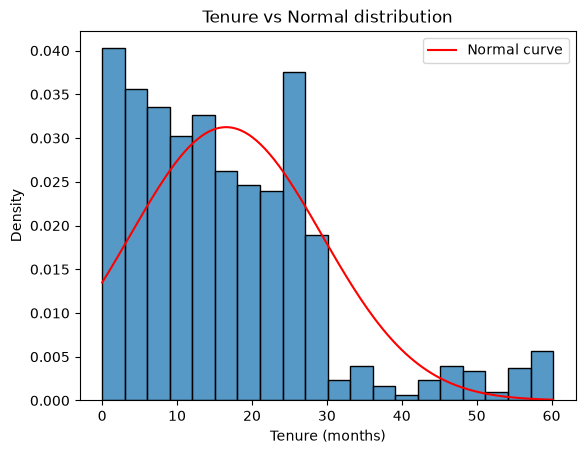

In [47]:
x = process_data["tenure_months"]
mean, std = x.mean(), x.std()

sns.histplot(x, kde=False, stat="density", bins=20)
x_line = np.linspace(x.min(), x.max(), 200)
plt.plot(x_line, stats.norm.pdf(x_line, mean, std), color="red", label="Normal curve")
plt.xlabel("Tenure (months)")
plt.title("Tenure vs Normal distribution")
plt.legend()
plt.show()

The normal curve does not fit the data well. The real data has many new customer. 

2. The 68-95-99.7 rule

In [48]:
within1 = ((x >= mean - std) & (x <= mean + std)).mean() * 100
within2 = ((x >= mean - 2*std) & (x <= mean + 2*std)).mean() * 100
within3 = ((x >= mean - 3*std) & (x <= mean + 3*std)).mean() * 100
print(round(within1, 1), round(within2, 1), round(within3, 1))

76.6 94.0 97.2


76.6% of customers are within 1 standard deviation of the mean tenure, 94% are within 2 standard deviations, and 97.2% are within 3 standard deviations. Too many customers are close to the mean, and there are too many extreme values, so the data does not follow the Normal rule.

3. Q-Q plot

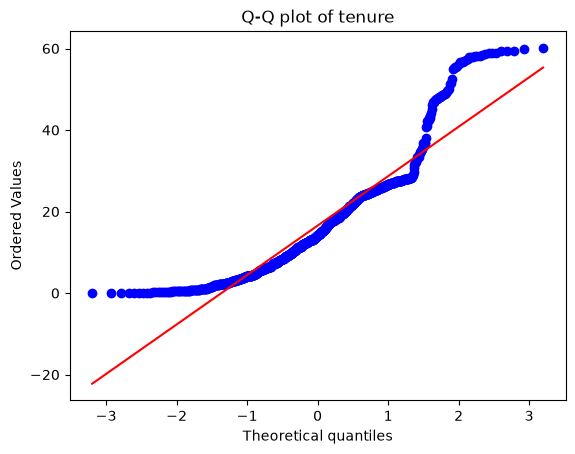

In [49]:
stats.probplot(x, dist="norm", plot=plt)
plt.title("Q-Q plot of tenure")
plt.show()

The points do not follow the red line. This confirms that tenure is not normal.

4. Skewness and kurtosis

In [50]:
print("Skewness:", round(x.skew(), 2))
print("Kurtosis:", round(x.kurt(), 2))

Skewness: 1.22
Kurtosis: 1.74


5. Model vs Reality

In [51]:
print("Normal says P(tenure > 30):", round(1 - stats.norm.cdf(30, mean, std), 3))
print("Real data P(tenure > 30):", round((x > 30).mean(), 3))

Normal says P(tenure > 30): 0.146
Real data P(tenure > 30): 0.086


The normal model predicts that 14.6% of customers have more than 30 months of tenure, but in reality only 8.6% do. Using the normal woult overestimate the number of long lasting customers.

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">5. Comparison</h2>
</div>

In [52]:
print(20 * p, 20 * (1 - p), lam)

14.014014014014013 5.9859859859859865 0.995995995995996


n·p = 20 × 0.70 = 14 and n·(1−p) = 20 × 0.30 = 6, both ≥ 5, so the Normal approximation is acceptable for the Binomial.
λ = 1.0, which is less than 10, so the Normal approximation is not suitable for the Poisson.